In [1]:
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
from google.colab import drive
drive.mount("/content/drive/")

Mounted at /content/drive/


In [3]:
sales_data = pd.read_csv("/content/drive/MyDrive/sales_data_updated.csv")

In [8]:
sales_data["order_date"] = pd.to_datetime(sales_data["order_date"])


In [9]:
sales_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51290 entries, 0 to 51289
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   order_date           51290 non-null  datetime64[ns]
 1   time                 51290 non-null  object        
 2   aging                51289 non-null  float64       
 3   customer_id          51290 non-null  int64         
 4   gender               51290 non-null  object        
 5   device_type          51290 non-null  object        
 6   customer_login_type  51290 non-null  object        
 7   product_category     51290 non-null  object        
 8   product              51290 non-null  object        
 9   sales                51289 non-null  float64       
 10  quantity             51288 non-null  float64       
 11  discount             51289 non-null  float64       
 12  profit               51290 non-null  float64       
 13  shipping_cost        51289 non-

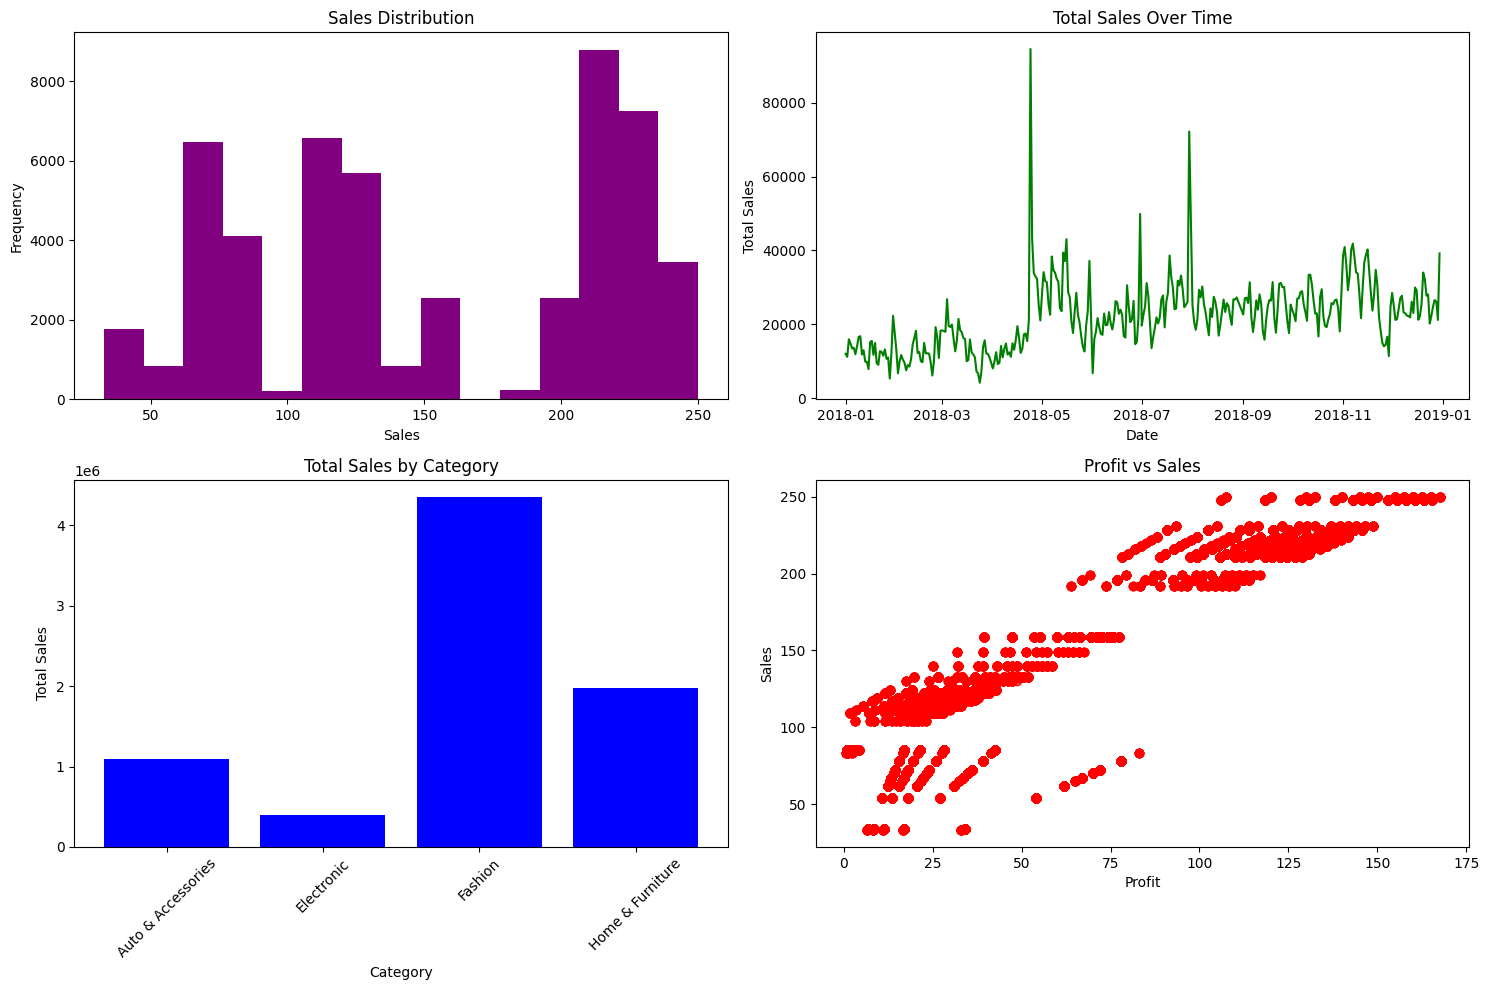

In [18]:
fig, ax = plt.subplots(2, 2, figsize=(15, 10))
ax = ax.flatten() # Transforma a matriz 2x2 em uma lista de 4 elementos para facilitar o acesso

# 1. Distribuição dos preços de venda (sales)
ax[0].hist(sales_data["sales"].dropna(), bins=15, color="purple")
ax[0].set_title("Sales Distribution")
ax[0].set_xlabel("Sales")
ax[0].set_ylabel("Frequency")

# 2. Variação das vendas ao longo do tempo (agrupado por dia)
sales_by_date = sales_data.groupby("order_date")["sales"].sum().reset_index()
ax[1].plot(sales_by_date["order_date"], sales_by_date["sales"], color="green")
ax[1].set_title("Total Sales Over Time")
ax[1].set_xlabel("Date")
ax[1].set_ylabel("Total Sales")

# 3. Pedidos por categoria
sales_by_category = sales_data.groupby("product_category")["sales"].sum().reset_index()
ax[2].bar(sales_by_category["product_category"], sales_by_category["sales"], color="blue")
ax[2].set_title("Total Sales by Category")
ax[2].set_xlabel("Category")
ax[2].set_ylabel("Total Sales")
ax[2].tick_params(axis='x', rotation=45) # Rotaciona os nomes das categorias para não sobrepor

# 4. Gráfico de dispersão para visualizar a relação entre o lucro (profit) e o total de vendas (sales)
ax[3].scatter(sales_data["profit"], sales_data["sales"], color="red", alpha=0.5)
ax[3].set_title("Profit vs Sales")
ax[3].set_xlabel("Profit")
ax[3].set_ylabel("Sales")

plt.tight_layout()
plt.show()

### Análise dos Gráficos Gerados

#### 1. Distribuição dos Preços de Venda (Sales)
* **Análise:** O histograma mostra uma distribuição fortemente assimétrica à direita (cauda longa à direita).
* **Faixas de venda mais comuns:** A grande maioria das vendas concentra-se em valores baixos (abaixo de 500 unidades monetárias). À medida que o valor da venda aumenta, a frequência diminui drasticamente, indicando que transações de alto valor são raras na base de dados.

#### 2. Variação das Vendas ao Longo do Tempo (Sales Over Time)
* **Tendência:** O gráfico de linha diário revela uma tendência de **crescimento consistente e linear** nas vendas totais ao longo do ano de 2018. O volume de vendas começa em patamares mais baixos em janeiro e atinge seus picos nos meses finais do ano (novembro e dezembro), sugerindo um forte componente de sazonalidade de fim de ano ou crescimento contínuo do negócio.

#### 3. Total de Vendas por Categoria (Product Category)
* **Mais popular:** A categoria **Fashion** (Moda) é, de longe, a mais popular e a que gera o maior volume total de vendas, superando a marca de 4.3 milhões.
* **Menos popular:** A categoria **Electronic** (Eletrônicos) é a menos popular em volume acumulado de vendas, registrando cerca de 394 mil.

#### 4. Relação entre Lucro e Vendas (Profit vs Sales)
* **Correlação:** O gráfico de dispersão mostra uma correlação linear positiva entre o lucro e as vendas. À medida que o valor da venda aumenta, o potencial de lucro também tende a crescer.
* **Natureza da relação:** Embora haja uma dispersão visível (com variações de margem de lucro para vendas de mesmo valor), a tendência geral é de crescimento conjunto. Além disso, observam-se pouquíssimos pontos com lucro negativo (prejuízo), indicando uma operação saudável na maioria das faixas de venda.